# Portfolio Project 2: Imbalanced Fraud Detection

> Practice rare-event evaluation, precision-recall trade-offs, and safe threshold selection.

**Track:** Machine Learning Roadmap · **Language:** English

## Project brief
This notebook uses a synthetic transaction dataset to demonstrate rare-event detection. The challenge is to identify a small number of positives without overwhelming investigators with false alarms. These data are artificial and must not be presented as real fraud statistics.

(2400, 7) fraud prevalence: 0.03


,transaction_id,amount,hour,new_device,international,transactions_last_hour,is_fraud
0,T000000,24.81,2,1,0,1.17,0
1,T000001,180.60,17,1,0,3.71,0
2,T000002,49.02,11,0,0,7.90,0
3,T000003,503.90,14,0,0,2.19,0
4,T000004,87.91,11,0,0,2.25,0


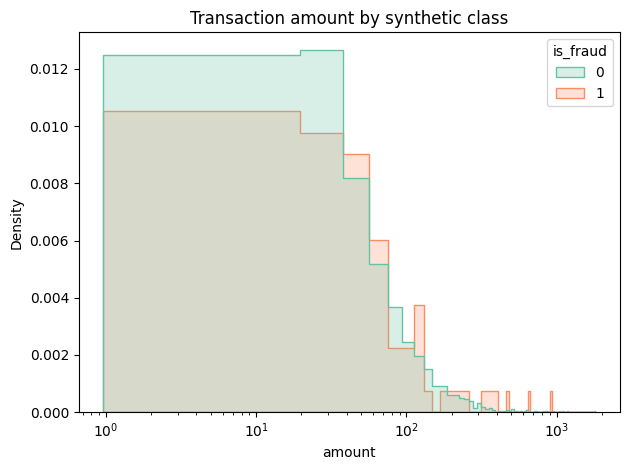

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_score,
                             recall_score, f1_score, PrecisionRecallDisplay, ConfusionMatrixDisplay)
path = Path("../datasets/transactions_synthetic.csv")
if not path.exists(): path = Path("datasets/transactions_synthetic.csv")
df = pd.read_csv(path)
print(df.shape, "fraud prevalence:", round(df["is_fraud"].mean(),4))
display(df.head())
sns.histplot(data=df, x="amount", hue="is_fraud", palette="Set2", stat="density", common_norm=False, element="step")
plt.xscale("log"); plt.title("Transaction amount by synthetic class"); plt.tight_layout()

Positive rate: 0.03
ROC-AUC: 0.481
Average precision: 0.029


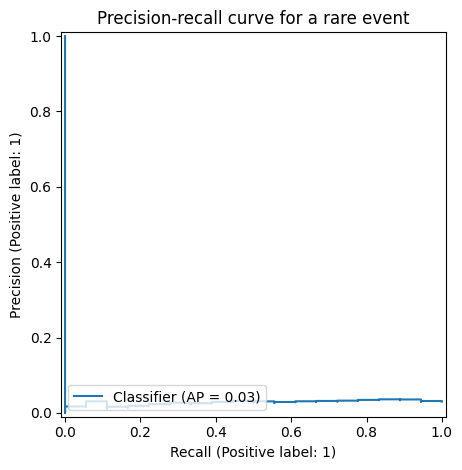

In [2]:
target="is_fraud"
features=[c for c in df.columns if c not in [target,"transaction_id"]]
X, y = df[features], df[target]
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=.25,stratify=y,random_state=42)
model = HistGradientBoostingClassifier(max_iter=120, learning_rate=.08, max_leaf_nodes=15, random_state=42).fit(X_train,y_train)
prob = model.predict_proba(X_test)[:,1]
print("Positive rate:",round(y_test.mean(),4))
print("ROC-AUC:",round(roc_auc_score(y_test,prob),3))
print("Average precision:",round(average_precision_score(y_test,prob),3))
PrecisionRecallDisplay.from_predictions(y_test,prob)
plt.title("Precision-recall curve for a rare event")
plt.tight_layout()

In [3]:
threshold_rows=[]
for threshold in [.05,.1,.2,.35,.5]:
    pred=(prob>=threshold).astype(int)
    threshold_rows.append({"threshold":threshold,"alert_rate":pred.mean(),"precision":precision_score(y_test,pred,zero_division=0),"recall":recall_score(y_test,pred,zero_division=0),"f1":f1_score(y_test,pred,zero_division=0)})
display(pd.DataFrame(threshold_rows).round(3))

,threshold,alert_rate,precision,recall,f1
0,0.05,0.102,0.016,0.056,0.025
1,0.10,0.043,0.000,0.000,0.000
2,0.20,0.023,0.000,0.000,0.000
3,0.35,0.010,0.000,0.000,0.000
4,0.50,0.000,0.000,0.000,0.000


## Operational reasoning
A useful fraud workflow usually includes an investigator-capacity constraint, delayed confirmed labels, asymmetric error costs, and changing fraud strategies. Choose a threshold based on validation data and operational trade-offs; do not select a threshold after repeatedly inspecting the final test set. Consider precision at top-k alerts and time-based validation for streaming transactions.

## Practice
Write a short model card that explains: dataset is synthetic, positive class is rare, why PR-AUC is useful, the cost of false positives, and what monitoring is needed after deployment.